# KrishiDrishti: Agronomy Rules

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.predict import districts, seasons, check_crops, recommend_crops

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

## Data

### Cleaned yield table saved by Main.ipynb

In [2]:
data = pd.read_csv("data/processed/model_a_data.csv")
latest_year = int(data["crop_year_start"].max())
print(data.shape, "| latest crop year:", latest_year)

(44833, 57) | latest crop year: 2024


### Soil health card: share of each district's samples that are saline or alkaline

In [3]:
master = pd.read_csv("data/processed/master_table.csv")
district_soil = master.drop_duplicates("district").set_index("district")[["soil_ec_saline_share", "soil_ph_alkaline_share"]]
district_soil.columns = ["saline_share", "alkaline_share"]
district_soil.describe().round(3)

,saline_share,alkaline_share
count,75.000,75.000
mean,0.014,0.008
std,0.069,0.027
min,0.000,0.000
25%,0.000,0.000
50%,0.001,0.001
75%,0.004,0.005
max,0.587,0.206


## Rule 1: Is the crop commonly grown in the district?

### Share of the district's season area under each crop (average of the last 3 crop years)

In [4]:
MIN_AREA_SHARE = 0.01
recent = data[data["crop_year_start"] > latest_year - 3]
grown = recent.groupby(["district", "season", "crop"], as_index=False)["area_ha"].mean()
grown["area_share"] = grown["area_ha"] / grown.groupby(["district", "season"])["area_ha"].transform("sum")
grown["rarely_grown"] = grown["area_share"] < MIN_AREA_SHARE
print(f"{len(grown):,} district-season-crop combinations | rarely grown: {grown['rarely_grown'].mean():.0%}")
grown[grown["district"] == "Agra"].sort_values(["season", "area_share"], ascending=[True, False]).round(4)

2,177 district-season-crop combinations | rarely grown: 51%


,district,season,crop,area_ha,area_share,rarely_grown
1,Agra,Kharif,Bajra,116819.4833,0.8723,False
9,Agra,Kharif,Rice,9915.7933,0.0740,False
6,Agra,Kharif,Jowar,2059.3067,0.0154,False
11,Agra,Kharif,Sesamum,1592.5367,0.0119,False
2,Agra,Kharif,Cotton(lint),1586.1133,0.0118,False
0,Agra,Kharif,Arhar/Tur,631.0667,0.0047,True
3,Agra,Kharif,Dry chillies,357.0000,0.0027,True
12,Agra,Kharif,Small millets,209.8400,0.0016,True
14,Agra,Kharif,Urad,200.3833,0.0015,True
13,Agra,Kharif,Sweet potato,180.0000,0.0013,True


### Share of districts where each crop is rarely grown

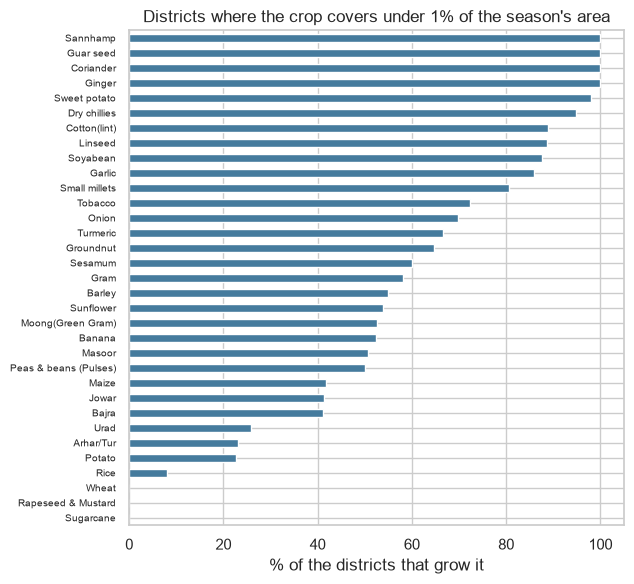

In [5]:
rare = grown.groupby("crop")["rarely_grown"].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(6.5, 6))
rare.plot.barh(color="#457b9d", ax=ax)
ax.set(title="Districts where the crop covers under 1% of the season's area", xlabel="% of the districts that grow it", ylabel="")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

## Rule 2: Does the crop need irrigation?

### Share of the crop's area that is irrigated in Uttar Pradesh (land-use statistics of 2010-11 to 2019-20)

In [6]:
NEEDS_IRRIGATION, MOSTLY_RAINFED = 0.85, 0.15
known = data[(data["crop_irrigated_share_known_prev"] == 1) & data["crop_year_start"].between(2011, 2020)]
irrigation = known.groupby(["crop", "season"]).apply(lambda g: pd.Series({
    "rows": len(g),
    "irrigated_share": np.average(g["crop_irrigated_share_prev"], weights=g["area_ha"]),
    "median_district_share": g["crop_irrigated_share_prev"].median()}))
irrigation["irrigation_need"] = np.select([irrigation["irrigated_share"] >= NEEDS_IRRIGATION,
                                           irrigation["irrigated_share"] <= MOSTLY_RAINFED],
                                          ["needs irrigation", "mostly rainfed"], "grown both ways")
irrigation.sort_values("irrigated_share", ascending=False).round(2)

,,rows,irrigated_share,median_district_share,irrigation_need
crop,season,,,,
Tobacco,Rabi,136.0,1.00,1.00,needs irrigation
Wheat,Rabi,744.0,0.99,1.00,needs irrigation
Sugarcane,Whole Year,713.0,0.96,1.00,needs irrigation
Rice,Summer,159.0,0.94,1.00,needs irrigation
Tobacco,Summer,34.0,0.92,1.00,needs irrigation
Sunflower,Summer,187.0,0.91,1.00,needs irrigation
Rapeseed & Mustard,Rabi,744.0,0.86,0.96,needs irrigation
Rice,Kharif,744.0,0.85,1.00,grown both ways
Barley,Rabi,694.0,0.73,0.93,grown both ways


### Crops with no irrigation statistics: typed in (irrigated vegetable crops)

In [7]:
typed_irrigation = {"Potato": "needs irrigation", "Onion": "needs irrigation", "Garlic": "needs irrigation"}
no_statistics = sorted(set(grown["crop"]) - set(irrigation.index.get_level_values("crop")))
pd.Series({crop: typed_irrigation.get(crop, "not known") for crop in no_statistics}, name="irrigation_need").to_frame()

,irrigation_need
Banana,not known
Coriander,not known
Cotton(lint),not known
Dry chillies,not known
Garlic,needs irrigation
Ginger,not known
Guar seed,not known
Onion,needs irrigation
Potato,needs irrigation
Sannhamp,not known


## Rule 3: Is the crop sensitive to the soil?

### Sensitivity of each crop to saline and to alkaline (sodic) soil: typed in from published classifications

In [8]:
sensitive_to_saline = ["Rice", "Maize", "Sugarcane", "Groundnut", "Linseed", "Potato", "Sweet potato", "Onion", "Sesamum",
                       "Arhar/Tur", "Gram", "Masoor", "Moong(Green Gram)", "Urad", "Peas & beans (Pulses)"]
tolerant_of_saline = ["Wheat", "Barley", "Jowar", "Soyabean", "Cotton(lint)", "Guar seed", "Rapeseed & Mustard"]
sensitive_to_alkaline = ["Maize", "Groundnut", "Arhar/Tur", "Gram", "Masoor", "Moong(Green Gram)", "Urad", "Peas & beans (Pulses)"]
tolerant_of_alkaline = ["Rice", "Wheat", "Barley", "Rapeseed & Mustard", "Bajra", "Sugarcane"]

tolerance = pd.DataFrame(index=pd.Index(sorted(grown["crop"].unique()), name="crop"),
                         columns=["sensitive_to_saline", "sensitive_to_alkaline"], dtype=object)
tolerance.loc[tolerance.index.isin(sensitive_to_saline), "sensitive_to_saline"] = True
tolerance.loc[tolerance.index.isin(tolerant_of_saline), "sensitive_to_saline"] = False
tolerance.loc[tolerance.index.isin(sensitive_to_alkaline), "sensitive_to_alkaline"] = True
tolerance.loc[tolerance.index.isin(tolerant_of_alkaline), "sensitive_to_alkaline"] = False
tolerance["source"] = "typed in: FAO Irrigation and Drainage Paper 29 (salinity); CSSRI Karnal (alkali soils)"
tolerance[["sensitive_to_saline", "sensitive_to_alkaline"]]

,sensitive_to_saline,sensitive_to_alkaline
crop,,
Arhar/Tur,True,True
Bajra,NaN,False
Banana,NaN,NaN
Barley,False,False
Coriander,NaN,NaN
Cotton(lint),False,NaN
Dry chillies,NaN,NaN
Garlic,NaN,NaN
Ginger,NaN,NaN


### Districts where saline or alkaline soil is common (at least 5% of the samples)

In [9]:
SOIL_SHARE = 0.05
district_soil["saline_common"] = district_soil["saline_share"] >= SOIL_SHARE
district_soil["alkaline_common"] = district_soil["alkaline_share"] >= SOIL_SHARE
print("Districts with saline soil common:", int(district_soil["saline_common"].sum()),
      "| alkaline soil common:", int(district_soil["alkaline_common"].sum()))
district_soil[district_soil["saline_common"] | district_soil["alkaline_common"]].sort_values("saline_share", ascending=False).round(3)

Districts with saline soil common: 3 | alkaline soil common: 3


,saline_share,alkaline_share,saline_common,alkaline_common
district,,,,
Rae bareli,0.587,0.016,True,False
Gautam buddha nagar,0.100,0.001,True,False
Mainpuri,0.084,0.019,True,False
Mathura,0.032,0.104,False,True
Aligarh,0.026,0.206,False,True
Amethi,0.005,0.052,False,True


### Check on history: yield relative to the state median, in districts with and without the problem soil

In [10]:
history = data[data["crop_year_start"] >= 2010].copy()
history["relative_yield"] = history["yield_t_per_ha"] / history.groupby(["crop", "season", "crop_year_start"])["yield_t_per_ha"].transform("median")
rows = []
for kind in ["saline", "alkaline"]:
    problem = history["district"].map(district_soil[f"{kind}_common"]).map({True: "problem", False: "elsewhere"})
    sensitivity = history["crop"].map(tolerance[f"sensitive_to_{kind}"]).map({True: "sensitive crops", False: "tolerant crops"})
    table = history.groupby([sensitivity, problem])["relative_yield"].agg(["median", "size"]).unstack()
    for group in table.index:
        rows.append({"soil": kind, "crops": group,
                     "relative_yield_elsewhere": table.loc[group, ("median", "elsewhere")],
                     "relative_yield_in_problem_districts": table.loc[group, ("median", "problem")],
                     "rows_in_problem_districts": table.loc[group, ("size", "problem")]})
soil_check = pd.DataFrame(rows).set_index(["soil", "crops"])
soil_check.round(3)

relative_yield_elsewhere  relative_yield_in_problem_districts  rows_in_problem_districts
soil     crops                                                                                                    
saline   sensitive crops                       1.0                                1.000                        685
         tolerant crops                        1.0                                1.000                        201
alkaline sensitive crops                       1.0                                1.000                        425
         tolerant crops                        1.0                                1.039                        262

## Rule 4: How old is the crop's yield data?

In [11]:
last_yield_year = data.groupby("crop")["crop_year_start"].max()
last_yield_year = last_yield_year[last_yield_year.index.isin(grown["crop"])]
last_yield_year[last_yield_year < latest_year - 1].rename("last_crop_year_with_yield").to_frame()

,last_crop_year_with_yield
crop,
Banana,2022
Coriander,2022
Dry chillies,2022
Garlic,2022
Ginger,2022
Guar seed,2022
Onion,2022
Potato,2022
Sweet potato,2022


## Save the Rules

In [12]:
rules = {
    "grown": grown.set_index(["district", "season", "crop"])[["area_share", "rarely_grown"]],
    "irrigation": irrigation[["irrigated_share", "irrigation_need"]],
    "typed_irrigation": typed_irrigation,
    "tolerance": tolerance,
    "district_soil": district_soil,
    "last_yield_year": {crop: int(year) for crop, year in last_yield_year.items()},
    "latest_year": latest_year,
    "thresholds": {"min_area_share": MIN_AREA_SHARE, "needs_irrigation": NEEDS_IRRIGATION,
                   "mostly_rainfed": MOSTLY_RAINFED, "soil_share": SOIL_SHARE},
}
Path("models").mkdir(exist_ok=True)
joblib.dump(rules, "models/rules.joblib")
print("Saved models/rules.joblib:", round(Path("models/rules.joblib").stat().st_size / 1e3), "KB")

Saved models/rules.joblib: 37 KB


### Check the saved rules through the interface functions

In [13]:
check_crops("Agra", "Rabi")

,area_share,irrigation_need,suitable,advice
crop,,,,
Potato,0.2512,needs irrigation,True,needs irrigation; official yield data ends 2022-23
Onion,0.0004,needs irrigation,True,rarely grown here (under 1% of the district's Rabi area); needs irrigation; official yield data ends 2022-23
Garlic,0.0000,needs irrigation,True,rarely grown here (under 1% of the district's Rabi area); needs irrigation; official yield data ends 2022-23
Wheat,0.4259,needs irrigation,True,needs irrigation
Barley,0.0245,grown both ways,True,
Peas & beans (Pulses),0.0002,grown both ways,True,rarely grown here (under 1% of the district's Rabi area)
Rapeseed & Mustard,0.2912,needs irrigation,True,needs irrigation
Gram,0.0040,grown both ways,True,rarely grown here (under 1% of the district's Rabi area)
Masoor,0.0024,grown both ways,True,rarely grown here (under 1% of the district's Rabi area)


In [14]:
check_crops("Agra", "Rabi", irrigated=False, soil={"saline": True, "alkaline": False})

,area_share,irrigation_need,suitable,advice
crop,,,,
Potato,0.2512,needs irrigation,False,"needs irrigation, which the farm does not have; sensitive to saline soil, which the farm's soil card shows; official..."
Onion,0.0004,needs irrigation,False,"rarely grown here (under 1% of the district's Rabi area); needs irrigation, which the farm does not have; sensitive ..."
Garlic,0.0000,needs irrigation,False,"rarely grown here (under 1% of the district's Rabi area); needs irrigation, which the farm does not have; official y..."
Wheat,0.4259,needs irrigation,False,"needs irrigation, which the farm does not have"
Barley,0.0245,grown both ways,True,
Peas & beans (Pulses),0.0002,grown both ways,True,"rarely grown here (under 1% of the district's Rabi area); sensitive to saline soil, which the farm's soil card shows"
Rapeseed & Mustard,0.2912,needs irrigation,False,"needs irrigation, which the farm does not have"
Gram,0.0040,grown both ways,True,"rarely grown here (under 1% of the district's Rabi area); sensitive to saline soil, which the farm's soil card shows"
Masoor,0.0024,grown both ways,True,"rarely grown here (under 1% of the district's Rabi area); sensitive to saline soil, which the farm's soil card shows"


In [15]:
shown = ["farm_predicted_t_ha", "predicted_price", "profit_rs_per_ha", "profit_range_low", "profit_range_high", "suitable", "advice"]
recommend_crops("Agra", "Rabi", irrigated=True)[shown]

,farm_predicted_t_ha,predicted_price,profit_rs_per_ha,profit_range_low,profit_range_high,suitable,advice
crop,,,,,,,
Peas & beans (Pulses),2.46,7112.0,134800.0,55000.0,224300.0,True,rarely grown here (under 1% of the district's Rabi area)
Rapeseed & Mustard,1.95,7301.0,100300.0,46800.0,146600.0,True,
Gram,1.69,7879.0,92900.0,17500.0,196000.0,True,rarely grown here (under 1% of the district's Rabi area)
Potato,36.38,688.0,83300.0,-43000.0,266500.0,True,official yield data ends 2022-23
Wheat,4.16,2548.0,63000.0,27400.0,93600.0,True,
Masoor,1.04,6927.0,40200.0,11900.0,78800.0,True,rarely grown here (under 1% of the district's Rabi area)
Barley,3.11,2288.0,30200.0,100.0,58600.0,True,
Onion,16.81,NaN,NaN,NaN,NaN,True,rarely grown here (under 1% of the district's Rabi area); official yield data ends 2022-23
Garlic,6.20,NaN,NaN,NaN,NaN,True,rarely grown here (under 1% of the district's Rabi area); official yield data ends 2022-23


In [16]:
recommend_crops("Agra", "Rabi", irrigated=False)[shown]

,farm_predicted_t_ha,predicted_price,profit_rs_per_ha,profit_range_low,profit_range_high,suitable,advice
crop,,,,,,,
Peas & beans (Pulses),2.46,7112.0,134800.0,55000.0,224300.0,True,rarely grown here (under 1% of the district's Rabi area)
Gram,1.69,7879.0,92900.0,17500.0,196000.0,True,rarely grown here (under 1% of the district's Rabi area)
Masoor,1.04,6927.0,40200.0,11900.0,78800.0,True,rarely grown here (under 1% of the district's Rabi area)
Barley,3.11,2288.0,30200.0,100.0,58600.0,True,
Coriander,0.75,NaN,NaN,NaN,NaN,True,rarely grown here (under 1% of the district's Rabi area); official yield data ends 2022-23
Rapeseed & Mustard,1.95,7301.0,100300.0,46800.0,146600.0,False,"needs irrigation, which the farm does not have"
Potato,36.38,688.0,83300.0,-43000.0,266500.0,False,"needs irrigation, which the farm does not have; official yield data ends 2022-23"
Wheat,4.16,2548.0,63000.0,27400.0,93600.0,False,"needs irrigation, which the farm does not have"
Onion,16.81,NaN,NaN,NaN,NaN,False,"rarely grown here (under 1% of the district's Rabi area); needs irrigation, which the farm does not have; official y..."


### How often does a rule change the top crop of a farm without irrigation?

In [17]:
rows = []
for district in districts():
    for season in seasons(district):
        with_water = recommend_crops(district, season, irrigated=True)
        without = recommend_crops(district, season, irrigated=False)
        if "profit_rs_per_ha" in with_water and with_water["profit_rs_per_ha"].notna().any():
            rows.append({"district": district, "season": season, "top_irrigated": with_water.index[0],
                         "top_without_irrigation": without.index[0],
                         "top_has_a_note": with_water["advice"].iloc[0] != ""})
tops = pd.DataFrame(rows)
tops["changed"] = tops["top_irrigated"] != tops["top_without_irrigation"]
display(tops.groupby("season")[["changed", "top_has_a_note"]].mean().mul(100).round(0))
tops.groupby(["season", "top_without_irrigation"]).size().rename("districts").to_frame()

,changed,top_has_a_note
season,,
Kharif,0.0,23.0
Rabi,92.0,69.0
Summer,0.0,21.0


districts
season top_without_irrigation           
Kharif Arhar/Tur                      60
       Rice                            1
       Urad                           14
Rabi   Gram                           54
       Masoor                         19
       Peas & beans (Pulses)           2
Summer Moong(Green Gram)              63